1. Setup, sementes e função auxiliar de experimento

In [1]:
import sys
from pathlib import Path
import importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import src.train
import src.models
importlib.reload(src.train)
importlib.reload(src.models)

from src.train import set_seed, prepare_dataset, treinar_modelo, make_dataloaders
from src.models import MLP

RANDOM_STATE = 42
SEEDS_ESTUDO = [42, 100, 202]  # Mínimo de 3 sementes exigido pelo PDF
BATCH_SIZE_BASE = 256

set_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

reg_data = prepare_dataset(
    csv_path=str(ROOT_DIR / "data" / "processed" / "dataset_regression.csv"),
    task="regression",
    target_col="TARGET",
    random_state=RANDOM_STATE,
    batch_size=BATCH_SIZE_BASE,
)

clf_data = prepare_dataset(
    csv_path=str(ROOT_DIR / "data" / "processed" / "dataset_classification.csv"),
    task="classification",
    target_col="TARGET",
    random_state=RANDOM_STATE,
    batch_size=BATCH_SIZE_BASE,
)

LOGS_DIR = ROOT_DIR / "logs"
LOGS_DIR.mkdir(parents=True, exist_ok=True)
LOG_CSV = LOGS_DIR / "hiperparametros.csv"


def criar_otimizador(nome_opt: str, params, lr: float, weight_decay: float = 0.0):
    if nome_opt == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    elif nome_opt == "AdamW":
        return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    elif nome_opt == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=0.0, weight_decay=weight_decay)
    elif nome_opt == "SGD_momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    elif nome_opt == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Otimizador não suportado: {nome_opt}")


def rodar_configuracao_multi_sementes(
    task: str,
    data_dict: dict,
    hiperparam_testado: str,
    valor_label: str,
    hidden_units=(64, 32),
    activation: str = "ReLU",
    dropout: float = 0.0,
    optimizer_name: str = "Adam",
    lr: float = 1e-3,
    batch_size: int = 256,
    weight_decay: float = 0.0,
    n_epocas: int = 60,
    paciencia: int = 12,
    seeds=SEEDS_ESTUDO,
    salvar_csv: bool = True,
):
    loss_fn = torch.nn.MSELoss() if task == "regression" else torch.nn.BCEWithLogitsLoss()
    linhas = []
    historicos = []

    for s in seeds:
        set_seed(s)

        # Recria DataLoaders caso batch_size mude em relação ao padrão
        if batch_size != BATCH_SIZE_BASE:
            dl_tr, dl_va, _ = make_dataloaders(
                data_dict["scaled_splits"]["X_train"],
                data_dict["scaled_splits"]["y_train"],
                data_dict["scaled_splits"]["X_val"],
                data_dict["scaled_splits"]["y_val"],
                data_dict["scaled_splits"]["X_test"],
                data_dict["scaled_splits"]["y_test"],
                task=task,
                batch_size=batch_size,
                seed=s,
            )
        else:
            dl_tr = data_dict["loaders"]["train"]
            dl_va = data_dict["loaders"]["val"]

        modelo = MLP(
            in_features=data_dict["n_features"],
            out_features=1,
            hidden_units=hidden_units,
            activation=activation,
            dropout=dropout,
        ).to(device)

        otim = criar_otimizador(optimizer_name, modelo.parameters(), lr=lr, weight_decay=weight_decay)
        res = treinar_modelo(
            modelo=modelo,
            dl_treino=dl_tr,
            dl_val=dl_va,
            loss_fn=loss_fn,
            otimizador=otim,
            device=device,
            n_epocas=n_epocas,
            paciencia=paciencia,
        )

        melhor_ep = res["melhor_epoca"]
        perda_tr_melhor = res["historico"]["treino"][melhor_ep - 1]
        perda_va_melhor = res["melhor_val"]
        gap_melhor = perda_va_melhor - perda_tr_melhor
        n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

        registro = {
            "task": task,
            "hiperparametro": hiperparam_testado,
            "valor": str(valor_label),
            "seed": s,
            "hidden_units": str(hidden_units),
            "n_params": n_params,
            "activation": activation,
            "optimizer": optimizer_name,
            "lr": lr,
            "batch_size": batch_size,
            "weight_decay": weight_decay,
            "dropout": dropout,
            "melhor_epoca": melhor_ep,
            "epocas_rodadas": res["epocas_rodadas"],
            "perda_treino_melhor": perda_tr_melhor,
            "perda_val_melhor": perda_va_melhor,
            "gap_val_menos_treino": gap_melhor,
            "tempo_s": res["tempo_s"],
        }
        linhas.append(registro)
        historicos.append((s, res["historico"]))

    df_run = pd.DataFrame(linhas)
    if salvar_csv:
        if LOG_CSV.exists():
            df_antigo = pd.read_csv(LOG_CSV)
            df_total = pd.concat([df_antigo, df_run], ignore_index=True)
        else:
            df_total = df_run
        df_total.to_csv(LOG_CSV, index=False)

    return df_run, historicos

Rodando em: cpu


2. Estudo 1: Neurônios por camada (Regressão e Classificação)

          task     valor  n_params  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification (128, 64)      9089        0.227742      0.008229  -0.016889      89.714943
classification   (16, 8)       241        0.286115      0.005703  -0.003110      75.346225
classification  (32, 16)       737        0.265706      0.018970  -0.005154      85.398585
classification  (64, 32)      2497        0.239782      0.009546  -0.006368      73.739542
classification    (8, 4)        89        0.286672      0.046944  -0.006182      72.852975
    regression (128, 64)      8833        0.001181      0.000011  -0.000395      71.059436
    regression   (16, 8)       209        0.001465      0.000146  -0.000289      76.686102
    regression  (32, 16)       673        0.001206      0.000020  -0.000333      71.486959
    regression  (64, 32)      2369        0.001213      0.000029  -0.000380      42.691660
    regression    (8, 4)        73        0.002023      0.000392  -0.000212      82.093221

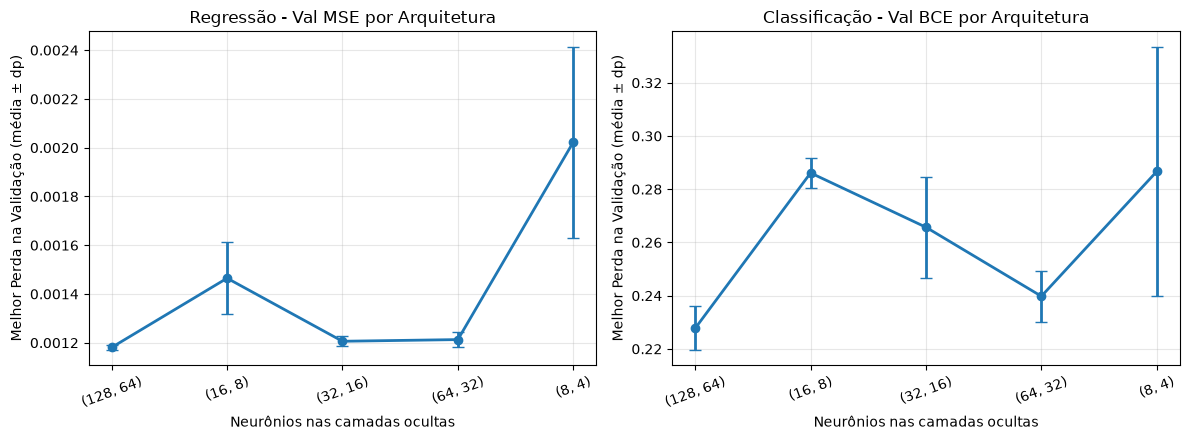

In [2]:
configuracoes_neuronios = [
    (8, 4),
    (16, 8),
    (32, 16),
    (64, 32),   # baseline
    (128, 64),
]

dfs_neuronios = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for arch in configuracoes_neuronios:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="neuronios_por_camada",
            valor_label=str(arch),
            hidden_units=arch,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_neuronios.append(df_r)

df_neur = pd.concat(dfs_neuronios, ignore_index=True)

resumo_neur = (
    df_neur.groupby(["task", "valor", "n_params"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_neur.to_string(index=False))

fig_dir = ROOT_DIR / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Arquitetura"),
    (axes[1], "classification", "Classificação - Val BCE por Arquitetura"),
]:
    sub = resumo_neur[resumo_neur["task"] == t_nome]
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Neurônios nas camadas ocultas")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_01_neuronios_por_camada.png", dpi=150, bbox_inches="tight")
plt.show()

3. Taxa de aprendizado ($\eta$ / lr)

          task  valor  val_loss_media  val_loss_std  gap_media  epocas_media  tempo_s_media
classification 0.0001        0.416656      0.005275   0.001147     50.000000      72.882584
classification 0.0005        0.318077      0.006385  -0.002459     50.000000      68.892712
classification  0.001        0.237609      0.003851  -0.012889     50.000000      69.198120
classification  0.005        0.179213      0.011966  -0.056422     41.333333      71.231663
classification   0.01        0.175527      0.002494  -0.061285     50.000000      76.369051
    regression 0.0001        0.001190      0.000006  -0.000236     50.000000      75.758976
    regression 0.0005        0.001183      0.000009  -0.000310     36.000000      51.632481
    regression  0.001        0.001203      0.000015  -0.000362     26.666667      36.663318
    regression  0.005        0.001252      0.000023  -0.000566     26.333333      40.863602
    regression   0.01        0.001364      0.000045  -0.000895     20.333333    

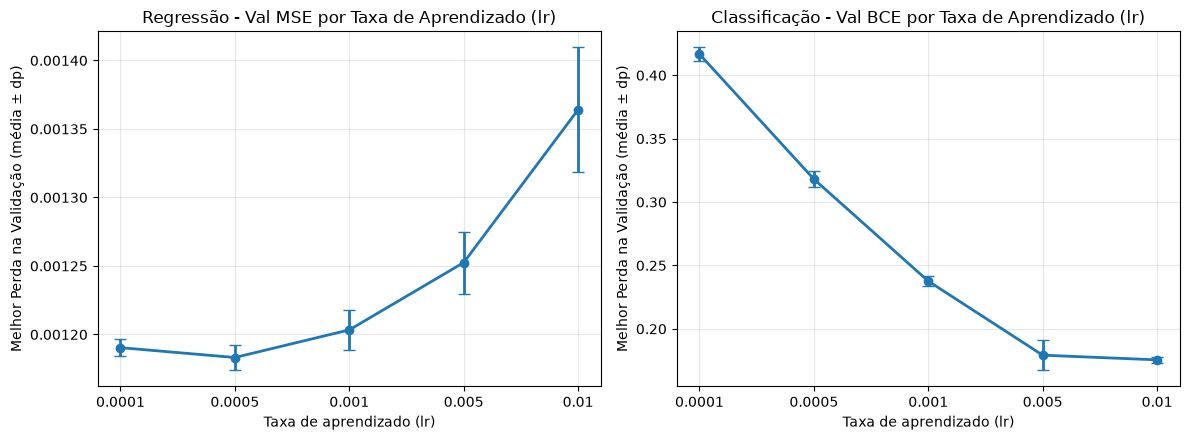

In [3]:
valores_lr = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]

dfs_lr = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for lr_val in valores_lr:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="taxa_de_aprendizado_lr",
            valor_label=f"{lr_val:g}",
            hidden_units=(64, 32),
            activation="ReLU",
            optimizer_name="Adam",
            lr=lr_val,
            batch_size=BATCH_SIZE_BASE,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_lr.append(df_r)

df_lr = pd.concat(dfs_lr, ignore_index=True)

resumo_lr = (
    df_lr.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        epocas_media=("epocas_rodadas", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_lr.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Taxa de Aprendizado (lr)"),
    (axes[1], "classification", "Classificação - Val BCE por Taxa de Aprendizado (lr)"),
]:
    sub = resumo_lr[resumo_lr["task"] == t_nome].copy()
    sub["lr_num"] = sub["valor"].astype(float)
    sub = sub.sort_values("lr_num")
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Taxa de aprendizado (lr)")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_02_taxa_de_aprendizado.png", dpi=150, bbox_inches="tight")
plt.show()

4. Estudo de Hiperparâmetros: Número de Camadas Ocultas

          task                  valor  n_params  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification                1 (64,)       449        0.371939      0.002147   0.000331      78.381102
classification             2 (64, 32)      2497        0.241135      0.003808  -0.008912      87.144702
classification         3 (64, 32, 16)      3009        0.124288      0.019487  -0.065123      83.507611
classification 5 (64, 64, 32, 32, 16)      8225        0.340306      0.030037  -0.035093      46.165552
    regression                1 (64,)       321        0.001213      0.000012  -0.000280      49.379026
    regression             2 (64, 32)      2369        0.001225      0.000027  -0.000365      38.478413
    regression         3 (64, 32, 16)      2881        0.001234      0.000013  -0.000439      43.752918
    regression 5 (64, 64, 32, 32, 16)      8097        0.001313      0.000138  -0.000687      40.610803


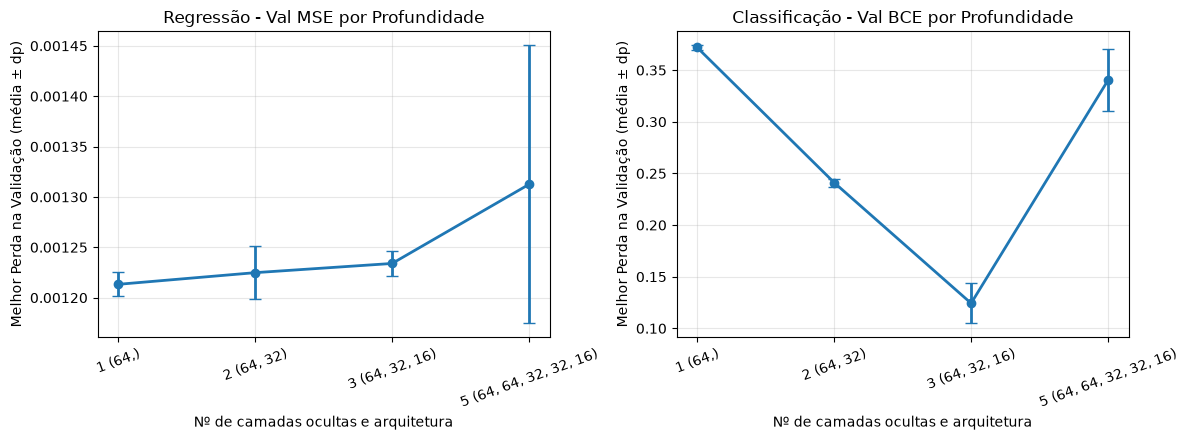

In [4]:
configuracoes_camadas = [
    (64,),
    (64, 32),           # baseline (2 camadas)
    (64, 32, 16),
    (64, 64, 32, 32, 16),
]

dfs_camadas = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for arch in configuracoes_camadas:
        n_camadas = len(arch)
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="numero_de_camadas_ocultas",
            valor_label=f"{n_camadas} {arch}",
            hidden_units=arch,
            activation="ReLU",
            optimizer_name="Adam",
            lr=1e-3,
            batch_size=BATCH_SIZE_BASE,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_camadas.append(df_r)

df_cam = pd.concat(dfs_camadas, ignore_index=True)

resumo_cam = (
    df_cam.groupby(["task", "valor", "n_params"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_cam.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Profundidade"),
    (axes[1], "classification", "Classificação - Val BCE por Profundidade"),
]:
    sub = resumo_cam[resumo_cam["task"] == t_nome].copy()
    sub["n_cam"] = sub["valor"].str.split().str[0].astype(int)
    sub = sub.sort_values("n_cam")
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Nº de camadas ocultas e arquitetura")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_03_numero_de_camadas.png", dpi=150, bbox_inches="tight")
plt.show()

5. Estudo de Hiperparâmetros: Função de Ativação

          task     valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification      GELU        0.299695      0.002794  -0.006871      93.277158
classification LeakyReLU        0.244171      0.008923  -0.010744      81.501393
classification      ReLU        0.243210      0.003718  -0.010402      85.718757
classification   Sigmoid        0.348883      0.001632  -0.000417      84.555506
classification      Tanh        0.209704      0.003885  -0.021503      77.852163
    regression      GELU        0.001185      0.000009  -0.000334      59.139190
    regression LeakyReLU        0.001222      0.000001  -0.000371      31.708114
    regression      ReLU        0.001200      0.000007  -0.000375      45.282302
    regression   Sigmoid        0.001182      0.000008  -0.000291      58.011912
    regression      Tanh        0.001222      0.000056  -0.000358      41.243325


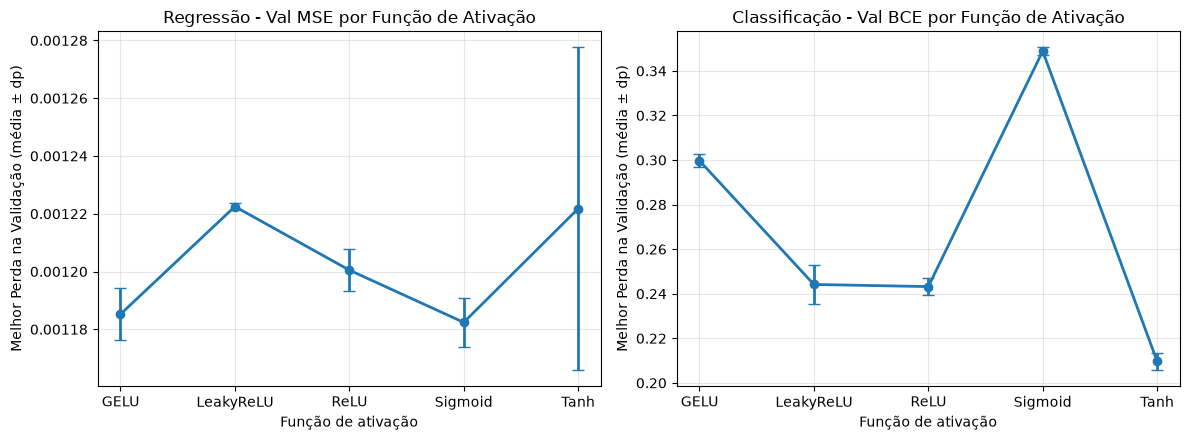

In [5]:
ativacoes_teste = ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "GELU"]

dfs_ativ = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for act_nome in ativacoes_teste:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="funcao_de_ativacao",
            valor_label=act_nome,
            hidden_units=(64, 32),
            activation=act_nome,
            optimizer_name="Adam",
            lr=1e-3,
            batch_size=BATCH_SIZE_BASE,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_ativ.append(df_r)

df_ativ = pd.concat(dfs_ativ, ignore_index=True)

resumo_ativ = (
    df_ativ.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_ativ.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Função de Ativação"),
    (axes[1], "classification", "Classificação - Val BCE por Função de Ativação"),
]:
    sub = resumo_ativ[resumo_ativ["task"] == t_nome]
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Função de ativação")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_04_funcao_de_ativacao.png", dpi=150, bbox_inches="tight")
plt.show()

6. Estudo de Hiperparâmetros: Otimizador

          task        valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification         Adam        0.231698      0.013041  -0.012477      86.981291
classification        AdamW        0.242117      0.016381  -0.005257      81.280441
classification      RMSprop        0.335563      0.005583  -0.020269      87.581920
classification          SGD        0.501816      0.001159   0.000083      73.433187
classification SGD_momentum        0.475857      0.018629  -0.000045      87.729706
    regression         Adam        0.001214      0.000022  -0.000365      37.000083
    regression        AdamW        0.001202      0.000002  -0.000369      45.874251
    regression      RMSprop        0.001212      0.000032  -0.000588      42.751687
    regression          SGD        0.005744      0.000394  -0.000011      75.585497
    regression SGD_momentum        0.001436      0.000012  -0.000198      73.306633


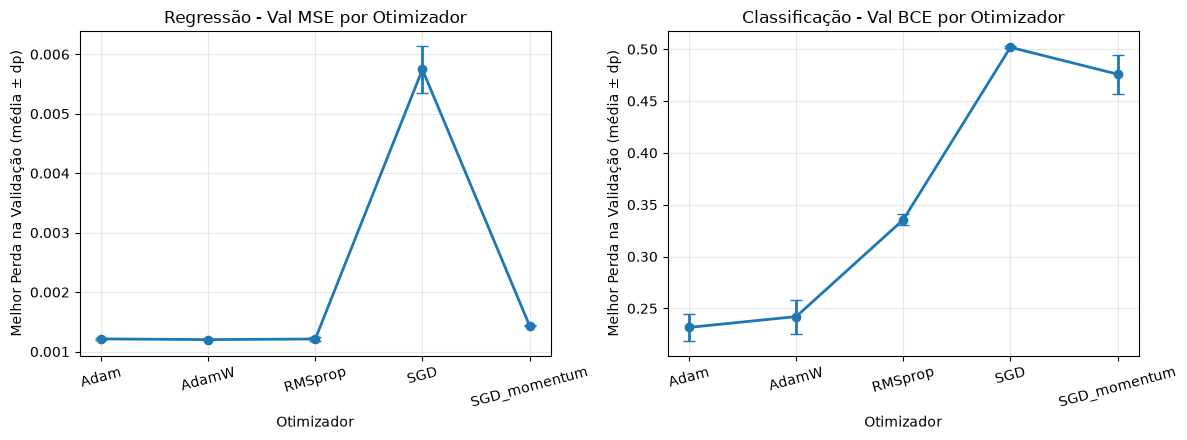

In [8]:
otimizadores_teste = ["SGD", "SGD_momentum", "RMSprop", "Adam", "AdamW"]

dfs_otim = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for opt_nome in otimizadores_teste:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="otimizador",
            valor_label=opt_nome,
            hidden_units=(64, 32),
            activation="ReLU",
            optimizer_name=opt_nome,
            lr=1e-3,
            batch_size=BATCH_SIZE_BASE,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_otim.append(df_r)

df_otim = pd.concat(dfs_otim, ignore_index=True)

resumo_otim = (
    df_otim.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_otim.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Otimizador"),
    (axes[1], "classification", "Classificação - Val BCE por Otimizador"),
]:
    sub = resumo_otim[resumo_otim["task"] == t_nome]
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Otimizador")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_05_otimizador.png", dpi=150, bbox_inches="tight")
plt.show()

7. Estudo de Hiperparâmetros: Tamanho de Lote (batch_size)

          task valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification    64        0.161533      0.015282  -0.044726     190.328636
classification   128        0.179672      0.004634  -0.019157     127.846529
classification   256        0.240701      0.005928  -0.016394      84.479268
classification   512        0.290823      0.002459  -0.002378      77.716754
    regression    64        0.001268      0.000081  -0.000497      91.783175
    regression   128        0.001197      0.000016  -0.000396      91.190187
    regression   256        0.001241      0.000024  -0.000346      25.314561
    regression   512        0.001203      0.000016  -0.000321      41.993617


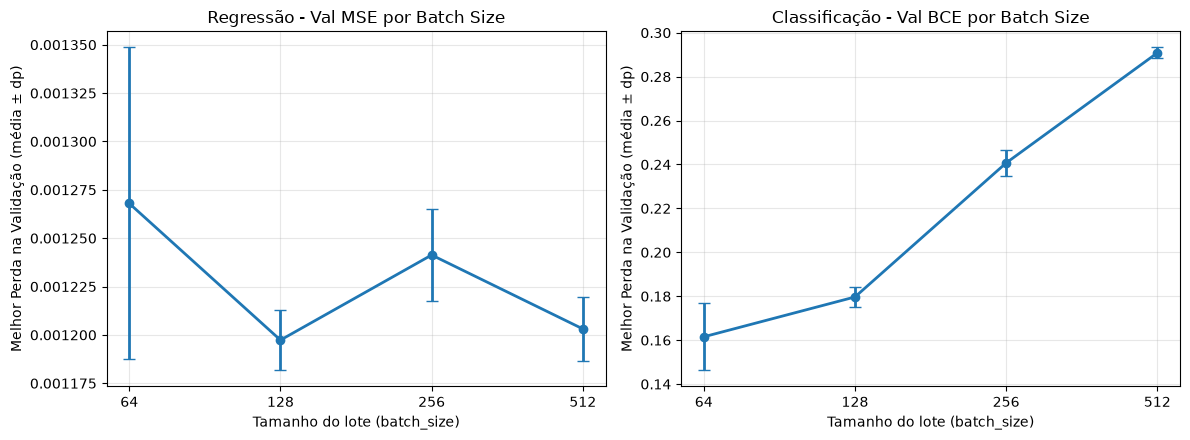

In [9]:
batches_teste = [64, 128, 256, 512]

dfs_batch = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for b_size in batches_teste:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="tamanho_de_lote_batch_size",
            valor_label=str(b_size),
            hidden_units=(64, 32),
            activation="ReLU",
            optimizer_name="Adam",
            lr=1e-3,
            batch_size=b_size,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_batch.append(df_r)

df_batch = pd.concat(dfs_batch, ignore_index=True)

resumo_batch = (
    df_batch.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
resumo_batch["b_num"] = resumo_batch["valor"].astype(int)
resumo_batch = resumo_batch.sort_values(["task", "b_num"])
print(resumo_batch.drop(columns=["b_num"]).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Batch Size"),
    (axes[1], "classification", "Classificação - Val BCE por Batch Size"),
]:
    sub = resumo_batch[resumo_batch["task"] == t_nome]
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Tamanho do lote (batch_size)")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_06_tamanho_de_lote.png", dpi=150, bbox_inches="tight")
plt.show()

8. Estudo de Hiperparâmetros: Dropout

          task valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification   0.0        0.233624      0.010258  -0.012250      93.912538
classification   0.1        0.057199      0.003493  -0.054087      90.694844
classification   0.2        0.077695      0.015501  -0.056074      82.142516
classification   0.3        0.090002      0.003155  -0.079466      92.969059
    regression   0.0        0.001226      0.000039  -0.000378      35.416212
    regression   0.1        0.001891      0.000310  -0.010349      69.850445
    regression   0.2        0.002396      0.000579  -0.022545      45.693103
    regression   0.3        0.002816      0.000579  -0.035535      47.174101


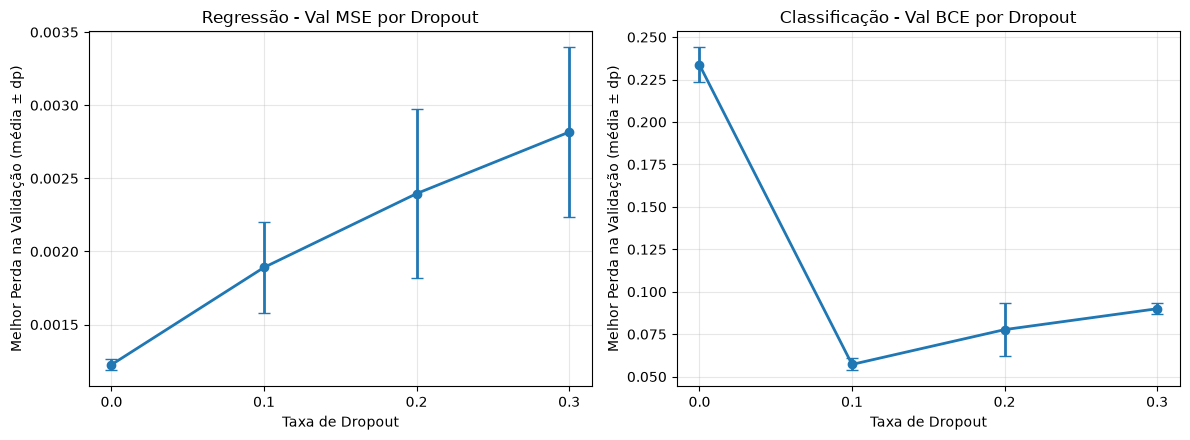

In [10]:
dropouts_teste = [0.0, 0.1, 0.2, 0.3]

dfs_drop = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for drop_val in dropouts_teste:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="dropout",
            valor_label=f"{drop_val:.1f}",
            hidden_units=(64, 32),
            activation="ReLU",
            optimizer_name="Adam",
            lr=1e-3,
            batch_size=BATCH_SIZE_BASE,
            dropout=drop_val,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_drop.append(df_r)

df_drop = pd.concat(dfs_drop, ignore_index=True)

resumo_drop = (
    df_drop.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
print(resumo_drop.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Dropout"),
    (axes[1], "classification", "Classificação - Val BCE por Dropout"),
]:
    sub = resumo_drop[resumo_drop["task"] == t_nome].sort_values("valor")
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Taxa de Dropout")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_07_dropout.png", dpi=150, bbox_inches="tight")
plt.show()

9. Estudo de Hiperparâmetros: Weight Decay (L2)

          task  valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
classification      0        0.241008      0.009830  -0.007474      86.903279
classification  1e-05        0.235602      0.006434  -0.011576      77.443600
classification 0.0001        0.237904      0.018052  -0.008293      80.955226
classification  0.001        0.242167      0.001346  -0.009259      86.581927
    regression      0        0.001201      0.000012  -0.000386      41.125592
    regression  1e-05        0.001195      0.000005  -0.000367      55.595773
    regression 0.0001        0.001212      0.000024  -0.000374      42.729349
    regression  0.001        0.001194      0.000004  -0.000373      43.801888


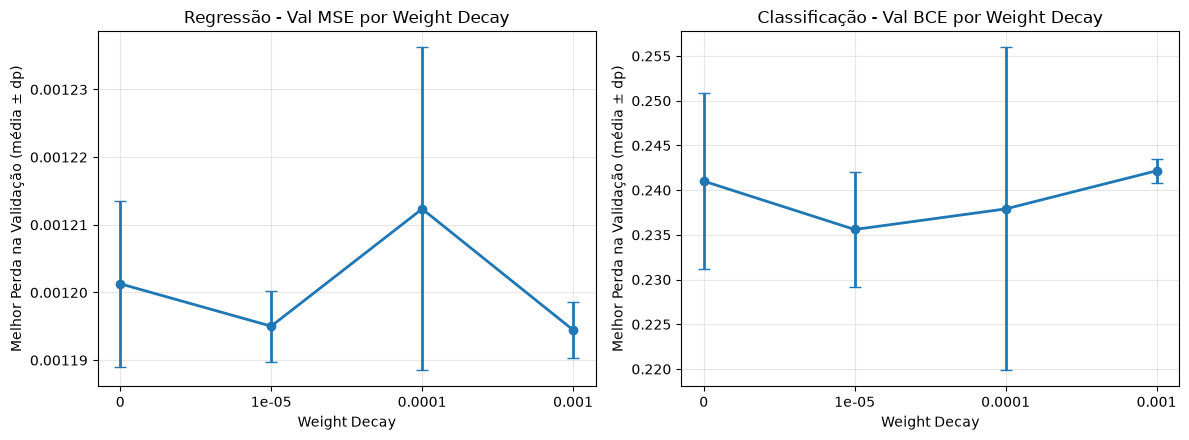

In [11]:
wd_valores = [0.0, 1e-5, 1e-4, 1e-3]

dfs_wd = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for wd_val in wd_valores:
        df_r, _ = rodar_configuracao_multi_sementes(
            task=task_nome,
            data_dict=d_dict,
            hiperparam_testado="weight_decay",
            valor_label=f"{wd_val:g}",
            hidden_units=(64, 32),
            activation="ReLU",
            optimizer_name="AdamW",
            lr=1e-3,
            batch_size=BATCH_SIZE_BASE,
            dropout=0.0,
            weight_decay=wd_val,
            n_epocas=50,
            paciencia=10,
            seeds=SEEDS_ESTUDO,
            salvar_csv=True,
        )
        dfs_wd.append(df_r)

df_wd = pd.concat(dfs_wd, ignore_index=True)

resumo_wd = (
    df_wd.groupby(["task", "valor"], as_index=False)
    .agg(
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
)
resumo_wd["wd_num"] = resumo_wd["valor"].astype(float)
resumo_wd = resumo_wd.sort_values(["task", "wd_num"])
print(resumo_wd.drop(columns=["wd_num"]).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Val MSE por Weight Decay"),
    (axes[1], "classification", "Classificação - Val BCE por Weight Decay"),
]:
    sub = resumo_wd[resumo_wd["task"] == t_nome]
    ax.errorbar(
        sub["valor"],
        sub["val_loss_media"],
        yerr=sub["val_loss_std"],
        marker="o",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Weight Decay")
    ax.set_ylabel("Melhor Perda na Validação (média ± dp)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "hp_08_weight_decay.png", dpi=150, bbox_inches="tight")
plt.show()

10. Interação em 2D: Mapa de Calor (lr × batch_size)

ValueError: Index contains duplicate entries, cannot reshape

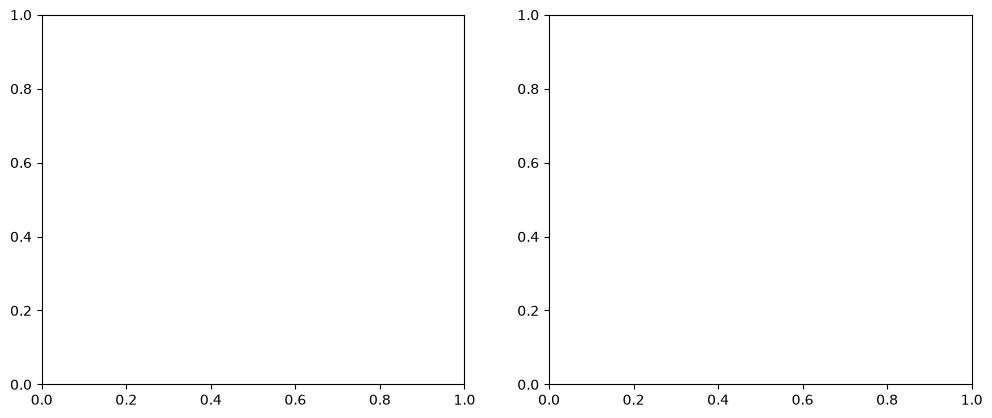

In [12]:
lrs_grid = [5e-4, 1e-3, 5e-3]
batches_grid = [128, 256, 512]

dfs_grid = []
for task_nome, d_dict in [("regression", reg_data), ("classification", clf_data)]:
    for lr_v in lrs_grid:
        for b_v in batches_grid:
            df_r, _ = rodar_configuracao_multi_sementes(
                task=task_nome,
                data_dict=d_dict,
                hiperparam_testado="interacao_lr_batch_size",
                valor_label=f"lr={lr_v:g}|bs={b_v}",
                hidden_units=(64, 32),
                activation="ReLU",
                optimizer_name="Adam",
                lr=lr_v,
                batch_size=b_v,
                n_epocas=35,
                paciencia=8,
                seeds=SEEDS_ESTUDO,
                salvar_csv=True,
            )
            df_r["lr_grid"] = lr_v
            df_r["bs_grid"] = b_v
            dfs_grid.append(df_r)

df_grid = pd.concat(dfs_grid, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Média Val MSE (lr × batch_size)"),
    (axes[1], "classification", "Classificação - Média Val BCE (lr × batch_size)"),
]:
    sub = df_grid[df_grid["task"] == t_nome]
    piv = sub.pivot(index="lr_grid", columns="bs_grid", values="perda_val_melhor")
    # Reagrega por média caso haja mais de uma semente por célula do pivot
    piv_mean = sub.groupby(["lr_grid", "bs_grid"], as_index=False)["perda_val_melhor"].mean().pivot(
        index="lr_grid", columns="bs_grid", values="perda_val_melhor"
    )
    im = ax.imshow(piv_mean.values, aspect="auto")
    ax.set_xticks(range(len(piv_mean.columns)))
    ax.set_xticklabels(piv_mean.columns)
    ax.set_yticks(range(len(piv_mean.index)))
    ax.set_yticklabels([f"{v:g}" for v in piv_mean.index])
    ax.set_xlabel("batch_size")
    ax.set_ylabel("lr")
    ax.set_title(titulo)

    for i in range(len(piv_mean.index)):
        for j in range(len(piv_mean.columns)):
            val_cell = piv_mean.values[i, j]
            ax.text(j, i, f"{val_cell:.4f}", ha="center", va="center", color="white", fontsize=9)

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig(fig_dir / "hp_09_heatmap_lr_batch_size.png", dpi=150, bbox_inches="tight")
plt.show()

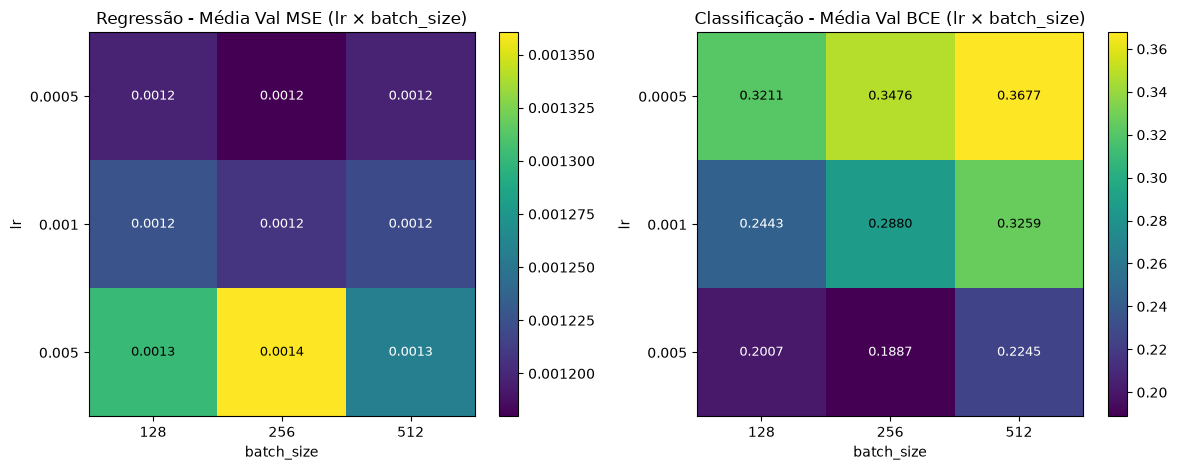

In [13]:
df_csv = pd.read_csv(LOG_CSV)
df_grid = df_csv[df_csv["hiperparametro"] == "interacao_lr_batch_size"].copy()

# Extrai lr e batch_size a partir da coluna 'valor' (ex.: "lr=0.0005|bs=128")
partes = df_grid["valor"].str.split("|", expand=True)
df_grid["lr_grid"] = partes[0].str.replace("lr=", "", regex=False).astype(float)
df_grid["bs_grid"] = partes[1].str.replace("bs=", "", regex=False).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, t_nome, titulo in [
    (axes[0], "regression", "Regressão - Média Val MSE (lr × batch_size)"),
    (axes[1], "classification", "Classificação - Média Val BCE (lr × batch_size)"),
]:
    sub = df_grid[df_grid["task"] == t_nome]
    piv_mean = (
        sub.groupby(["lr_grid", "bs_grid"], as_index=False)["perda_val_melhor"]
        .mean()
        .pivot(index="lr_grid", columns="bs_grid", values="perda_val_melhor")
        .sort_index()
    )
    im = ax.imshow(piv_mean.values, aspect="auto")
    ax.set_xticks(range(len(piv_mean.columns)))
    ax.set_xticklabels(piv_mean.columns)
    ax.set_yticks(range(len(piv_mean.index)))
    ax.set_yticklabels([f"{v:g}" for v in piv_mean.index])
    ax.set_xlabel("batch_size")
    ax.set_ylabel("lr")
    ax.set_title(titulo)

    vmin, vmax = piv_mean.values.min(), piv_mean.values.max()
    mid = (vmin + vmax) / 2
    for i in range(len(piv_mean.index)):
        for j in range(len(piv_mean.columns)):
            val_cell = piv_mean.values[i, j]
            cor_texto = "black" if val_cell > mid else "white"
            ax.text(j, i, f"{val_cell:.4f}", ha="center", va="center", color=cor_texto, fontsize=9)

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig(fig_dir / "hp_09_heatmap_lr_batch_size.png", dpi=150, bbox_inches="tight")
plt.show()

11. Consolidação e Seleção Final na Validação

In [15]:
df_hist = pd.read_csv(LOG_CSV)

resumo_geral = (
    df_hist.groupby(
        [
            "task",
            "hiperparametro",
            "valor",
            "hidden_units",
            "activation",
            "optimizer",
            "lr",
            "batch_size",
            "dropout",
            "weight_decay",
        ],
        as_index=False,
    )
    .agg(
        n_seeds=("seed", "nunique"),
        val_loss_media=("perda_val_melhor", "mean"),
        val_loss_std=("perda_val_melhor", "std"),
        gap_media=("gap_val_menos_treino", "mean"),
        tempo_s_media=("tempo_s", "mean"),
    )
    .sort_values(["task", "val_loss_media"])
)

melhores_por_task = resumo_geral.groupby("task", as_index=False).first()
melhores_por_task.to_csv(LOGS_DIR / "melhores_hiperparametros.csv", index=False)

for t_nome in ["regression", "classification"]:
    print(f"\n=== TOP 5 VALIDAÇÃO — {t_nome.upper()} ===")
    top5 = resumo_geral[resumo_geral["task"] == t_nome].head(5)
    print(
        top5[
            [
                "hiperparametro",
                "valor",
                "val_loss_media",
                "val_loss_std",
                "gap_media",
                "tempo_s_media",
            ]
        ].to_string(index=False)
    )


=== TOP 5 VALIDAÇÃO — REGRESSION ===
         hiperparametro            valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
interacao_lr_batch_size lr=0.0005|bs=256        0.001180      0.000012  -0.000306      51.645908
   neuronios_por_camada        (128, 64)        0.001181      0.000011  -0.000395      71.059436
     funcao_de_ativacao          Sigmoid        0.001182      0.000008  -0.000291      58.011912
 taxa_de_aprendizado_lr           0.0005        0.001183      0.000009  -0.000310      51.632481
     funcao_de_ativacao             GELU        0.001185      0.000009  -0.000334      59.139190

=== TOP 5 VALIDAÇÃO — CLASSIFICATION ===
            hiperparametro          valor  val_loss_media  val_loss_std  gap_media  tempo_s_media
                   dropout            0.1        0.057199      0.003493  -0.054087      90.694844
                   dropout            0.2        0.077695      0.015501  -0.056074      82.142516
                   dropout            0.3   